In [1]:
import numpy as np
import matplotlib.pyplot as plt

9875.083421720788
20140.372235897703


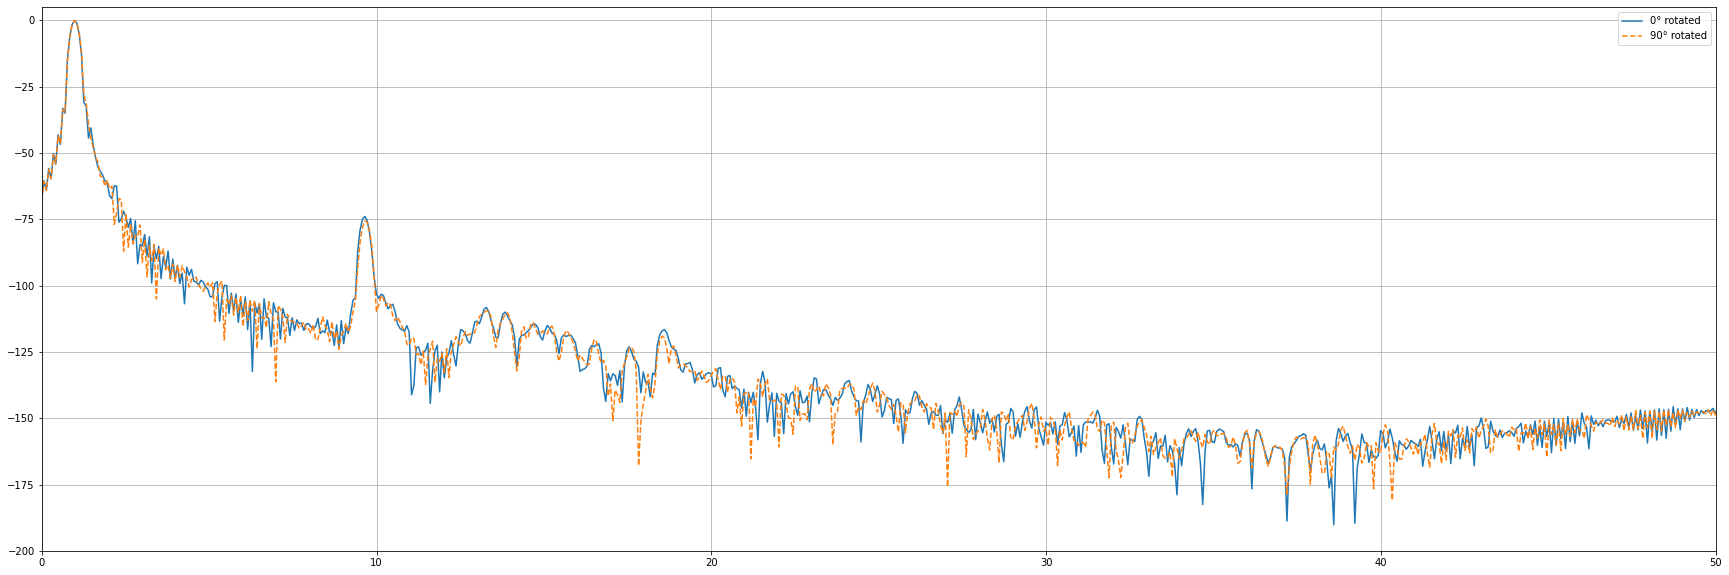

In [22]:
freqs = np.linspace(150e6,1200e6, 501)
df = (freqs[-1] - freqs[1])/(freqs.shape[0]-1)
# time domain samples
c = 299792458.
n_times = 1024

dt = 1./(n_times*df) 
xx = np.linspace(0, c*n_times*dt, 1024)/2#*1e9
#xx = np.linspace(0, 1024, 1024)

#print(299792458./df)

#window = np.kaiser(501,10)
window = np.hanning(501)
#window = np.ones(501)

plt.figure(figsize=(30,10))

i = 0

sim_dir = '/home/garten/Projekte/Programmierung/simulation_results/temporary/plane_plane/'

x = np.load(f'{sim_dir}/isotropic/sweep_postprocessing_results_0.npy')
abs_amp = np.max(np.abs(np.fft.ifft(x*window,1024)*np.linspace(1,1,1024)**2).T)
print(abs_amp)
plt.plot(xx, 20*np.log10(np.abs(np.fft.ifft(x*window,1024)*np.linspace(1,1,1024)**2).T/abs_amp), label=f'0° rotated')

x = np.load(f'{sim_dir}/isotropic_attitude/sweep_postprocessing_results_0.npy')
#x = np.load(f'{sim_dir}/isotropic_attitude/sweep_postprocessing_results_radargram.npy')[4]
#print(x)
abs_amp = np.max(np.abs(np.fft.ifft(x*window,1024)*np.linspace(1,1,1024)**2).T)
print(abs_amp)
plt.plot(xx, 20*np.log10(np.abs(np.fft.ifft(x*window,1024)*np.linspace(1,1,1024)**2).T/abs_amp), linestyle="dashed", label=f'90° rotated')

plt.xlim(0,50)
plt.ylim(-200,5)
plt.grid()
plt.legend()           

In [3]:
from tqdm.notebook import tqdm

In [28]:
n_samples=560

radargram = np.zeros((501, n_samples), dtype=complex)
radargram.shape
for i in tqdm(range(0,n_samples)):
    #radargram[:, i] = np.load(f'../SCIENCE_MEETING/validation/plane_sphere/SRC_RES_6_SPP_100/processed/sweep_{i}.npy')
    radargram[:, i] = np.load(f'../SCIENCE_MEETING/real/iDPR_larger_plane_more_samples/sweep_{i}.npy')
    #radargram[:, i] = np.load(f'../SCIENCE_MEETING/real/shallow/sweep_{i}.npy')
    #radargram[:, i] = np.load(f'../SCIENCE_MEETING/real/clutter/sweep_{i}.npy')

  0%|          | 0/560 [00:00<?, ?it/s]

In [23]:
from scipy.io  import savemat
msave = {'radargram' : radargram}
savemat("../radargrams/0203_radargram_iDPR_larger_bounds_0_560.mat", msave)

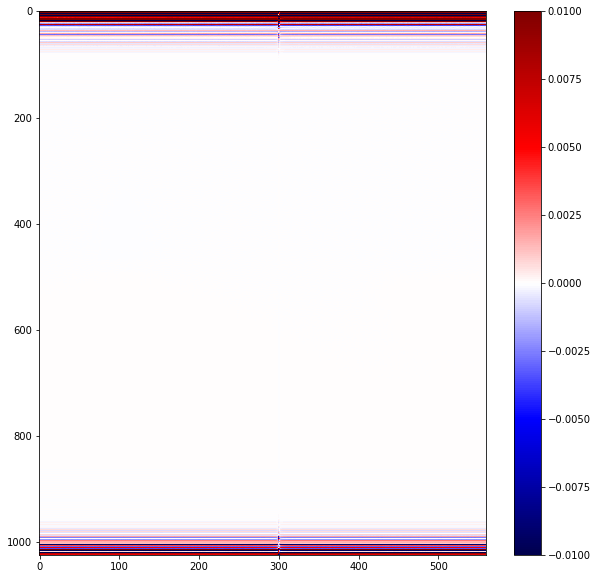

In [29]:
signal = np.real(np.fft.ifft(radargram.T*np.hanning(501),1024,axis=1)*np.linspace(1,1,1024)**2).T
plt.figure(figsize=(10,10))
abs_amp = np.max(np.abs(signal))
plt.imshow(signal/abs_amp,origin='upper',aspect='auto',cmap='seismic',vmin=-0.01,vmax=0.01)

#plt.ylim(200, 0)
#plt.xlim(75, 125)
plt.colorbar()

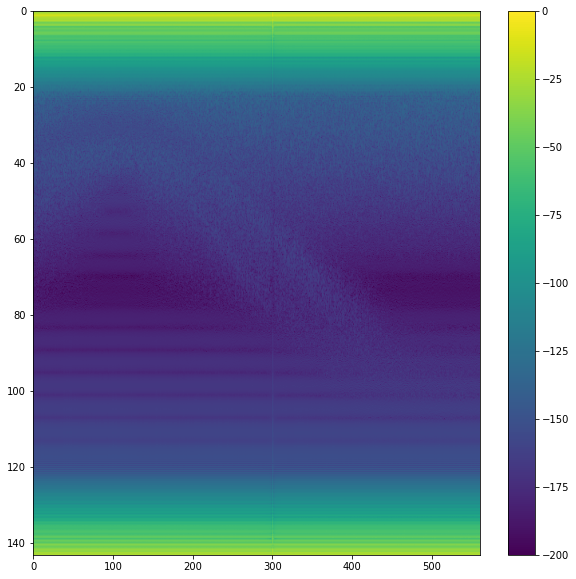

In [30]:
signal = np.abs(np.fft.ifft(radargram.T*np.hanning(501),1024,axis=1)*np.linspace(1,1,1024)**2).T
plt.figure(figsize=(10,10))
abs_amp = np.max(np.abs(signal))
plt.imshow(20*np.log10(signal/abs_amp),origin='upper',aspect='auto',vmin=-200,vmax=0, extent=(0, n_samples, xx[-1], 0))

#plt.ylim(50, 0)
#plt.xlim(0, 5)
plt.colorbar()